# M4 — Optimisation du seuil de décision COVID (validation)

**Sans réentraînement.** Charge le meilleur checkpoint de M4 fine-tuning phase 2, teste les seuils de 0,10 à 0,90 (pas de 0,05), compare à la règle d'origine et sauvegarde les courbes/CSV sur Drive.

Les seuils sont choisis **uniquement sur la validation**. Le jeu de test reste intact. Les sorties de ce notebook sont des analyses exploratoires, pas une estimation finale de performance.

**Attention** : si le runtime a été réinitialisé, réactiver la copie du dataset local (ou utiliser le ZIP).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

PROJECT_DIR = Path('/content/drive/MyDrive/Apprentissage/DS/projet')
DATASET_ROOT = Path('/content/COVID-19_Radiography_Dataset')
DRIVE_DATASET_ROOT = PROJECT_DIR / 'COVID-19_Radiography_Dataset'

# Copie facultative si les images locales ont disparu (décommenter au besoin).
if not DATASET_ROOT.exists():
     t0 = time.perf_counter()
     shutil.copytree(DRIVE_DATASET_ROOT, DATASET_ROOT)
     print('Copie en minutes :', (time.perf_counter() - t0)/60)

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f'Dataset absent : {DATASET_ROOT}. Décommenter la copie ci-dessus.')
print('GPU :', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
Copie en minutes : 19.031741417983334
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
val_df = pd.read_csv(PROJECT_DIR / 'validation.csv')

def local_filepath(original):
    normalized = str(original).replace('\\', '/')
    marker = 'COVID-19_Radiography_Dataset/'
    if marker not in normalized:
        raise ValueError(f'Chemin CSV inattendu : {original}')
    return str(DATASET_ROOT / normalized.split(marker, 1)[1])

val_df['filepath'] = val_df['filepath'].map(local_filepath)
assert len(val_df) == 3387, f'Nombre de lignes validation inattendu : {len(val_df)}'
assert val_df['filepath'].map(lambda p: Path(p).is_file()).all(), 'Images manquantes sur le disque local'
print('Images validation :', len(val_df))

Images validation : 3387


In [4]:
OUTPUT_DIR = PROJECT_DIR / 'M4_optimisation_seuil_COVID'
CHECKPOINT = PROJECT_DIR / 'M4_finetuning' / 'M4_FT2_B5_LR1e-6_best.keras'
OUTPUT_DIR.mkdir(exist_ok=True)
assert CHECKPOINT.is_file(), f'Checkpoint introuvable : {CHECKPOINT}'
# Même ordre de classes que dans le notebook M4 d'entraînement.
classes = sorted(pd.read_csv(PROJECT_DIR / 'train.csv')['class'].dropna().astype(str).unique().tolist())
val_df['class'] = val_df['class'].astype(str)
val_generator = ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_dataframe(
    val_df, x_col='filepath', y_col='class', classes=classes,
    target_size=(224,224), color_mode='rgb', class_mode='categorical',
    batch_size=32, shuffle=False)
print('Classes M4 :', val_generator.class_indices)
covid_matches = [c for c in classes if c.strip().upper() == 'COVID']
assert len(covid_matches) == 1, f'Classe COVID non identifiée : {classes}'
covid_idx = val_generator.class_indices[covid_matches[0]]
model = load_model(CHECKPOINT, compile=False)
val_generator.reset()
all_prob = np.asarray(model.predict(val_generator, verbose=1))
y_true_multiclass = np.asarray(val_generator.classes, dtype=int)
assert all_prob.shape == (len(y_true_multiclass), len(classes))
assert np.isfinite(all_prob).all()
y_prob = all_prob[:, covid_idx]
y_true = (y_true_multiclass == covid_idx).astype(int)

# Si p(COVID) >= seuil, on force COVID. Sinon, on choisit la meilleure
# des trois classes non-COVID. Le seuil ne s'applique donc qu'à COVID.
other_prob = all_prob.copy()
other_prob[:, covid_idx] = -np.inf
best_other = np.argmax(other_prob, axis=1)

def predict_multiclass_at_threshold(t):
    return np.where(y_prob >= t, covid_idx, best_other)

def predict_at_threshold(t):
    return (predict_multiclass_at_threshold(t) == covid_idx).astype(int)

# Baseline de M4 : argmax sur les quatre classes, SANS seuil 0.5.
baseline_pred = (np.argmax(all_prob, axis=1) == covid_idx).astype(int)
BASELINE_NAME = 'M4 argmax original'


Found 3387 validated image filenames belonging to 4 classes.
Classes M4 : {'COVID': 0, 'Lung_Opacity': 1, 'Normal': 2, 'Viral Pneumonia': 3}
106/106 ━━━━━━━━━━━━━━━━━━━━ 26s 234ms/step


In [5]:
def metrics_for(pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, pred, labels=[1], average=None, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(precision_COVID=float(p[0]), recall_COVID=float(r[0]),
                f1_COVID=float(f1[0]), FP=int(fp), FN=int(fn), TP=int(tp), TN=int(tn))

thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)
rows = [{'regle': f'seuil_{t:.2f}', 'seuil': float(t), **metrics_for(predict_at_threshold(t))}
        for t in thresholds]
results = pd.DataFrame(rows)
baseline = metrics_for(baseline_pred)
print('Règle initiale :', BASELINE_NAME, baseline)
print(results.to_string(index=False))
results.to_csv(OUTPUT_DIR / 'comparaison_seuils_validation.csv', index=False)
pd.DataFrame([{'regle': BASELINE_NAME, **baseline}]).to_csv(
    OUTPUT_DIR / 'baseline_validation.csv', index=False)

# Deux propositions explicites, sans toucher au test :
# 1) meilleur F1 COVID ; 2) meilleur recall parmi les seuils gardant
#    une précision COVID au moins égale à celle de la baseline.
max_f1 = results.sort_values(['f1_COVID','recall_COVID'], ascending=False).iloc[0]
eligible = results[results['precision_COVID'] >= baseline['precision_COVID']]
max_recall_constrained = (eligible.sort_values(['recall_COVID','f1_COVID'], ascending=False).iloc[0]
                          if len(eligible) else None)
print('\nMeilleur F1 :', max_f1[['seuil','precision_COVID','recall_COVID','f1_COVID','FN','FP']].to_dict())
print('Meilleur rappel avec précision >= baseline :',
      None if max_recall_constrained is None else
      max_recall_constrained[['seuil','precision_COVID','recall_COVID','f1_COVID','FN','FP']].to_dict())


Règle initiale : M4 argmax original {'precision_COVID': 0.9857397504456328, 'recall_COVID': 0.9550949913644214, 'f1_COVID': 0.9701754385964912, 'FP': 8, 'FN': 26, 'TP': 553, 'TN': 2800}
     regle  seuil  precision_COVID  recall_COVID  f1_COVID  FP  FN  TP   TN
seuil_0.10   0.10         0.947811      0.972366  0.959932  31  16 563 2777
seuil_0.15   0.15         0.958974      0.968912  0.963918  24  18 561 2784
seuil_0.20   0.20         0.962199      0.967185  0.964686  22  19 560 2786
seuil_0.25   0.25         0.970537      0.967185  0.968858  17  19 560 2791
seuil_0.30   0.30         0.975482      0.962003  0.968696  14  22 557 2794
seuil_0.35   0.35         0.978873      0.960276  0.969486  12  23 556 2796
seuil_0.40   0.40         0.980565      0.958549  0.969432  11  24 555 2797
seuil_0.45   0.45         0.982270      0.956822  0.969379  10  25 554 2798
seuil_0.50   0.50         0.985714      0.953368  0.969271   8  27 552 2800
seuil_0.55   0.55         0.987387      0.946459  0.96

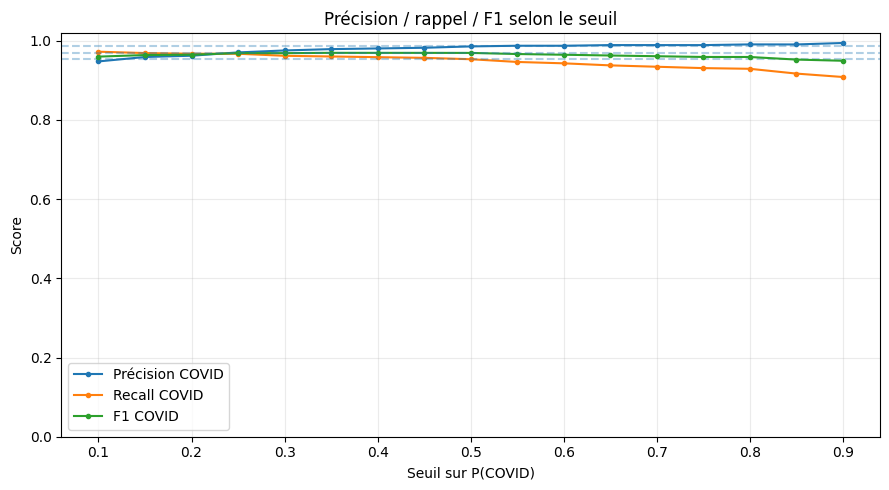

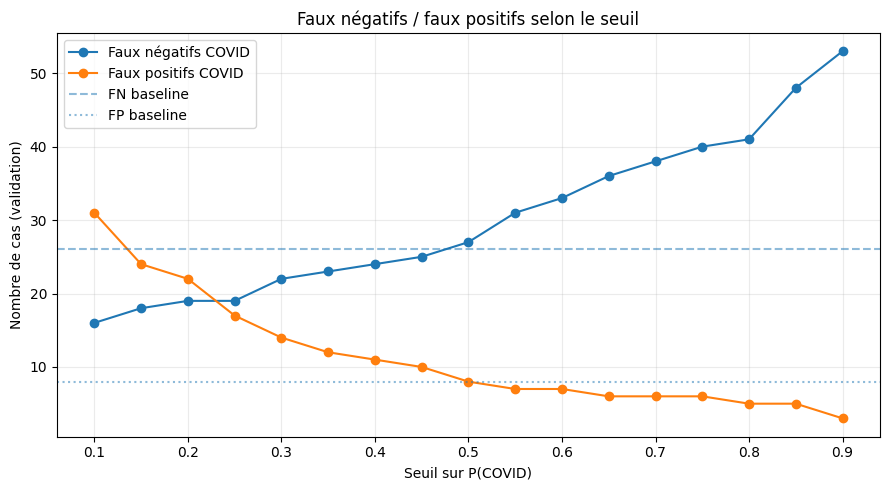

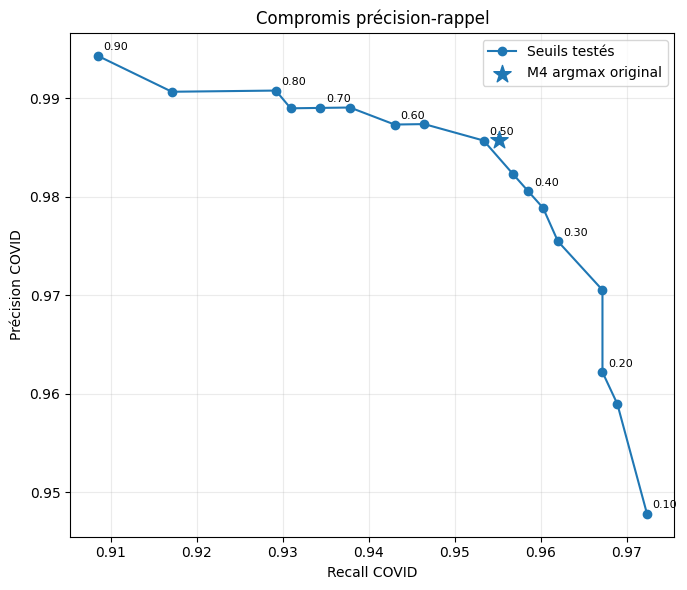

Résultats enregistrés dans : /content/drive/MyDrive/Apprentissage/DS/projet/M4_optimisation_seuil_COVID


In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for metric, label in [('precision_COVID','Précision COVID'),
                      ('recall_COVID','Recall COVID'),('f1_COVID','F1 COVID')]:
    ax.plot(results['seuil'], results[metric], marker='o', markersize=3, label=label)
    ax.axhline(baseline[metric], linestyle='--', alpha=.35)
ax.set(xlabel='Seuil sur P(COVID)', ylabel='Score', title='Précision / rappel / F1 selon le seuil')
ax.set_ylim(0, 1.02)
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'courbes_precision_recall_f1_vs_seuil.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(results['seuil'], results['FN'], 'o-', label='Faux négatifs COVID')
ax.plot(results['seuil'], results['FP'], 'o-', label='Faux positifs COVID')
ax.axhline(baseline['FN'], linestyle='--', alpha=.5, label='FN baseline')
ax.axhline(baseline['FP'], linestyle=':', alpha=.5, label='FP baseline')
ax.set(xlabel='Seuil sur P(COVID)', ylabel='Nombre de cas (validation)',
       title='Faux négatifs / faux positifs selon le seuil')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'courbes_FN_FP_vs_seuil.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(results['recall_COVID'], results['precision_COVID'], 'o-', label='Seuils testés')
ax.scatter([baseline['recall_COVID']], [baseline['precision_COVID']],
           marker='*', s=170, label=BASELINE_NAME, zorder=4)
for _, r in results.iloc[::2].iterrows():
    ax.annotate(f"{r['seuil']:.2f}", (r['recall_COVID'], r['precision_COVID']),
                xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set(xlabel='Recall COVID', ylabel='Précision COVID', title='Compromis précision-rappel')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'courbe_compromis_precision_recall.png', dpi=170)
plt.show()
print('Résultats enregistrés dans :', OUTPUT_DIR)


### Interprétation et sélection

Comparer d’abord la **baseline** et les seuils sur la validation. Ne pas choisir automatiquement le seuil au meilleur recall (il peut créer trop de faux positifs). Documenter la règle retenue et sa justification ; figer ensuite le seuil avant d’évaluer une seule fois le modèle final sur le jeu de test.

Pour M4, la baseline est **argmax**, et non « seuil 0,5 ». Les scores multiclasse des classes non-COVID peuvent changer avec la règle proposée ; les courbes ci-dessus évaluent uniquement COVID vs non-COVID, conformément à l'objectif de détection.